### Лабораторная работа №3: Гиперпараметры

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
#warnings.simplefilter("ignore")
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import (KFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, validation_curve)
from scipy.stats import randint, loguniform
import time

sns.set_theme(style="darkgrid")

In [ ]:
# Если нет доступа к UCI — положите CSV рядом с ноутбуком и укажите локальные пути:
# url_red = 'winequality-red.csv'
# url_white = 'winequality-white.csv'
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

df_red = pd.read_csv(url_red, sep=';')
df_red['color'] = 0  # 0 — красное вино

df_white = pd.read_csv(url_white, sep=';')
df_white['color'] = 1  # 1 — белое вино

# Объединяем в один датасет
df = pd.concat([df_red, df_white], ignore_index=True)

print("Общий размер объединенного датасета:", df.shape)
display(df.head())
df.info()

Общий размер объединенного датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


C:\Users\mrkir\AppData\Local\Temp\ipykernel_14916\3052066560.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='quality', palette='viridis')


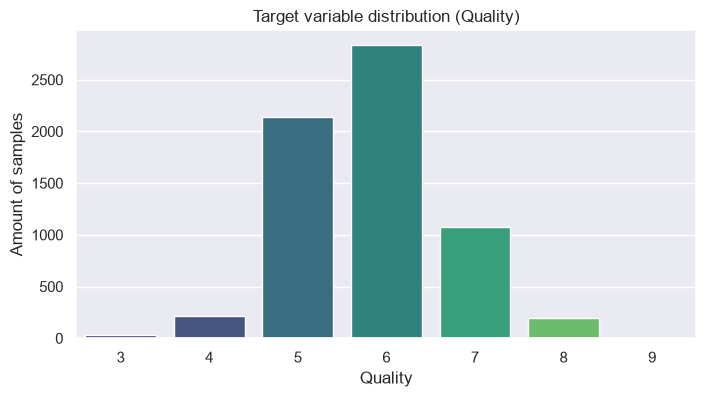

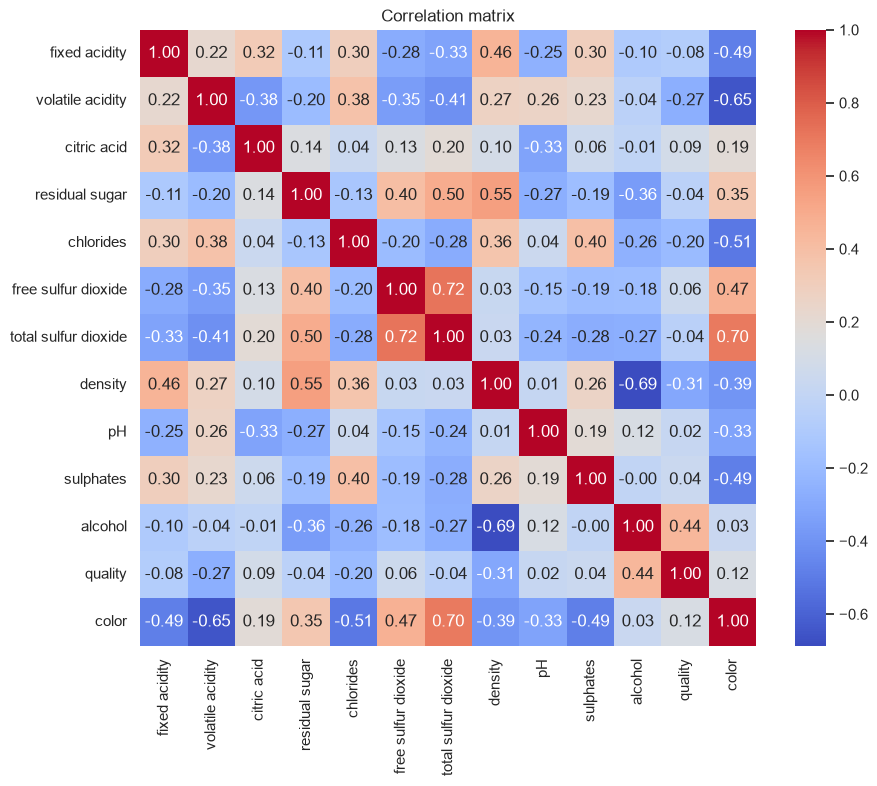

In [3]:
# Распределение целевой переменной (quality)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='quality', palette='viridis')
plt.title('Target variable distribution (Quality)')
plt.xlabel('Quality')
plt.ylabel('Amount of samples')
plt.show()

# Матрица корреляций
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation matrix')
plt.show()

## Разбиение и настройки эксперимента

In [4]:
# Настройки
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5      # число фолдов кросс-валидации
SCORING = 'neg_root_mean_squared_error'  # sklearn максимизирует score, поэтому RMSE со знаком «минус»

# Выделяем признаки (X) и целевую переменную (y)
X = df.drop(columns=['quality'])
y = df['quality']

# Разбиваем на Train (80%) и Test (20%)
# Выбор 80/20 — стандартный баланс между достаточностью данных для обучения и надежностью теста.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Размер обучающей выборки: {X_train.shape[0]} объектов")
print(f"Размер тестовой выборки: {X_test.shape[0]} объектов")

Размер обучающей выборки: 5197 объектов
Размер тестовой выборки: 1300 объектов


In [5]:
# Обучение Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_rmse = root_mean_squared_error(y_test, gb_pred)
gb_mae = mean_absolute_error(y_test, gb_pred)

# Обновляем итоговую таблицу результатов
results_df = pd.DataFrame({
    'Model': ['Gradient Boosting (Baseline)'],
    'RMSE': [gb_rmse],
    'MAE': [gb_mae]
})

display(results_df)

,Model,RMSE,MAE
0,Gradient Boosting (Baseline),0.678413,0.532242


## 1. Baseline: начальные параметры и качество

Baseline — `GradientBoostingRegressor` из лабораторной №1 с параметрами по умолчанию (кроме `n_estimators=100`):
`n_estimators=100`, `learning_rate=0.1`, `max_depth=3`, `subsample=1.0`, `min_samples_leaf=1`, `random_state=42`.

Качество на тесте уже записано выше: **RMSE = 0.678413, MAE = 0.532242**. Эти числа мы **не используем** для подбора — тест трогаем только в самом конце. Для честного сравнения с будущими моделями посчитаем CV-оценку baseline **только на train**.

In [6]:
# Единая схема кросс-валидации для ВСЕХ экспериментов (одинаковые фолды => честное сравнение)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

baseline_params = gb_model.get_params()
print({k: baseline_params[k] for k in ['n_estimators', 'learning_rate', 'max_depth', 'subsample', 'min_samples_leaf']})

baseline_cv = -cross_val_score(GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
                               X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
print(f"Baseline CV RMSE по фолдам: {np.round(baseline_cv, 4)}")
print(f"Baseline CV RMSE: {baseline_cv.mean():.4f} ± {baseline_cv.std():.4f}")

{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 1.0, 'min_samples_leaf': 1}
Baseline CV RMSE по фолдам: [0.7118 0.6651 0.6834 0.702  0.6759]
Baseline CV RMSE: 0.6876 ± 0.0171


## 2. Выбор гиперпараметров

Подбираем три гиперпараметра, которые сильнее всего управляют сложностью градиентного бустинга и связаны между собой. Остальные оставляем по умолчанию, чтобы не раздувать пространство поиска.

| Гиперпараметр | Что означает | Разумный диапазон | Ожидаемый эффект |
|---|---|---|---|
| `n_estimators` | число деревьев (итераций бустинга) | 50 … 400 | мало деревьев — недообучение; слишком много — переобучение (особенно при большом `learning_rate`); растёт время обучения |
| `learning_rate` | вклад каждого дерева в ансамбль (шаг «спуска») | 0.01 … 0.3 (логарифмическая шкала) | маленький шаг требует больше деревьев, но даёт более гладкую и устойчивую модель; большой — быстро обучается, но легко переобучается и «шумит» |
| `max_depth` | максимальная глубина каждого дерева | 1 … 5 | глубина 1–2 — слишком простые деревья (недообучение); глубокие деревья ловят взаимодействия признаков, но переобучаются |

**Почему именно они.** `n_estimators` и `learning_rate` — пара «компромисс»: их нужно подбирать вместе (малый шаг ↔ много деревьев). `max_depth` задаёт сложность одного слабого ученика. Остальные параметры (`subsample`, `min_samples_leaf`) вторичны — это регуляризаторы, их можно добавить в следующей итерации, но тогда пространство и время вырастут кратно.

## 3. Кросс-валидация

**Схема:** `KFold(n_splits=5, shuffle=True, random_state=42)`, применяется **только к train** (5197 объектов), тест в подборе не участвует.

**Почему 5 фолдов.**
- каждая модель обучается на 80% train (~4150 объектов), а валидируется на ~1040 — оценка достаточно стабильная;
- 10 фолдов дали бы чуть меньшее смещение оценки, но вдвое больше времени, а при перебирании сотен конфигураций это дорого;
- 3 фолда — каждая модель видит только 67% данных, оценка получается более пессимистичной и шумной.

Для регрессии стратификация не нужна (она для классов), поэтому обычный `KFold` с перемешиванием (в исходных данных объекты идут блоками «красное → белое»).

**Зачем нужна кросс-валидация и почему недостаточно одного train/test.**
Одно разбиение даёт одну оценку, которая зависит от того, какие объекты попали в валидацию. Разброс такой оценки неизвестен, и при выборе между близкими конфигурациями мы выбираем скорее удачное разбиение, чем лучшую модель. CV усредняет по K разбиениям и показывает ещё и разброс (std). Кроме того, каждый объект побывает и в обучении, и в валидации — данные используются эффективнее.

**Что будет, если подбирать гиперпараметры по тесту?** Тест превращается в ещё одну валидационную выборку: из множества конфигураций мы выбираем ту, которой «повезло» на этих 1300 объектах. Итоговая метрика на тесте оказывается **оптимистично завышенной** (утечка информации о тесте в выбор модели), и она перестаёт быть оценкой качества на новых данных. Поэтому в этой работе тест используется ровно один раз — для финальной оценки уже выбранных моделей.

In [7]:
def summarize_search(name, search, elapsed, n_candidates):
    """Краткая сводка по GridSearchCV / RandomizedSearchCV."""
    best = search.best_index_
    res = search.cv_results_
    print(f"=== {name} ===")
    print(f"Комбинаций гиперпараметров: {n_candidates}; фолдов: {CV_FOLDS}; всего обучений: {n_candidates * CV_FOLDS}")
    print(f"Лучшие параметры: {search.best_params_}")
    print(f"CV RMSE (лучшая конфигурация): {-res['mean_test_score'][best]:.4f} ± {res['std_test_score'][best]:.4f}")
    print(f"Время поиска: {elapsed:.1f} c")
    return {
        'Метод': name,
        'Комбинаций': n_candidates,
        'Обучений (комб.×фолды)': n_candidates * CV_FOLDS,
        'CV RMSE': -res['mean_test_score'][best],
        'CV std': res['std_test_score'][best],
        'Время, c': elapsed,
        'Лучшие параметры': search.best_params_,
    }

## 4. Grid Search

Пространство поиска (на основе рекомендаций из презентации для Wine + GB): 4 × 3 × 4 = **48 комбинаций**, при 5 фолдах — 240 обучений. Все значения `learning_rate` — в логарифмической сетке.

In [8]:
param_grid = {
    'n_estimators': [50, 100, 200, 400],
    'learning_rate': [0.01, 0.03, 0.1],
    'max_depth': [1, 2, 3, 4],
}
n_grid = int(np.prod([len(v) for v in param_grid.values()]))

grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid, scoring=SCORING, cv=cv,
    n_jobs=-1, refit=True, return_train_score=True,
)
t0 = time.perf_counter()
grid.fit(X_train, y_train)          # только train!
grid_time = time.perf_counter() - t0

grid_summary = summarize_search("Grid Search", grid, grid_time, n_grid)
grid_results = pd.DataFrame(grid.cv_results_)
grid_results.to_csv("grid_results.csv", index=False)   # сохраняем всю таблицу для анализа

=== Grid Search ===
Комбинаций гиперпараметров: 48; фолдов: 5; всего обучений: 240
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}
CV RMSE (лучшая конфигурация): 0.6636 ± 0.0171
Время поиска: 51.9 c


In [9]:
cols = ['param_n_estimators', 'param_learning_rate', 'param_max_depth', 'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']
top = grid_results.sort_values('rank_test_score')[cols].head(10).copy()
top['CV RMSE'] = -top.pop('mean_test_score')
top['Train RMSE'] = -top.pop('mean_train_score')
display(top.rename(columns={'std_test_score': 'CV std', 'rank_test_score': 'rank'}))

,param_n_estimators,param_learning_rate,param_max_depth,CV std,rank,CV RMSE,Train RMSE
47,400,0.10,4,0.017059,1,0.663641,0.411338
46,200,0.10,4,0.016145,2,0.669237,0.507578
31,400,0.03,4,0.017622,3,0.673461,0.562819
43,400,0.10,3,0.014972,4,0.674594,0.522534
45,100,0.10,4,0.018016,5,0.676407,0.574155
42,200,0.10,3,0.017089,6,0.680277,0.584800
30,200,0.03,4,0.018511,7,0.682479,0.608820
27,400,0.03,3,0.016592,8,0.685109,0.619634
44,50,0.10,4,0.018445,9,0.686756,0.619235
41,100,0.10,3,0.017063,10,0.687640,0.627712


## 5. Random Search

Для честного сравнения берём **тот же бюджет по числу комбинаций**: `N_ITER = 48` (столько же, сколько в сетке), тот же `cv` и та же метрика. Вместо фиксированных значений задаём распределения: `randint` для `n_estimators` и `max_depth`, `loguniform` для `learning_rate` (параметр, меняющийся на порядки, надо сэмплировать по логарифмической шкале). Диапазоны шире сетки по `learning_rate` и `n_estimators` — как раз преимущество случайного поиска: он пробует значения «между» узлами сетки.

In [10]:
N_ITER = n_grid   # тот же бюджет, что и у Grid Search

param_dist = {
    'n_estimators': randint(50, 401),
    'learning_rate': loguniform(0.01, 0.3),
    'max_depth': randint(1, 6),
}

rand = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_dist, n_iter=N_ITER,
    scoring=SCORING, cv=cv, n_jobs=-1, refit=True,
    random_state=RANDOM_STATE, return_train_score=True,
)
t0 = time.perf_counter()
rand.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

rand_summary = summarize_search("Random Search", rand, rand_time, N_ITER)
rand_results = pd.DataFrame(rand.cv_results_)
rand_results.to_csv("random_results.csv", index=False)

=== Random Search ===
Комбинаций гиперпараметров: 48; фолдов: 5; всего обучений: 240
Лучшие параметры: {'learning_rate': np.float64(0.18631003721334807), 'max_depth': 5, 'n_estimators': 378}
CV RMSE (лучшая конфигурация): 0.6534 ± 0.0197
Время поиска: 65.5 c


In [11]:
search_cmp = pd.DataFrame([grid_summary, rand_summary]).set_index('Метод')
display(search_cmp)

,Комбинаций,Обучений (комб.×фолды),CV RMSE,CV std,"Время, c",Лучшие параметры
Метод,,,,,,
Grid Search,48,240,0.663641,0.017059,51.926738,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti..."
Random Search,48,240,0.653400,0.019736,65.532220,"{'learning_rate': 0.18631003721334807, 'max_de..."


### Сравнение Grid и Random Search

Сравниваем по трём осям — **качество** (CV RMSE лучшей конфигурации), **число комбинаций** (оно одинаково, 48) и **время** (см. таблицу выше). Выводы — по числам в таблице: если разница в CV RMSE меньше `CV std`, методы по качеству эквивалентны.

**Когда Random Search предпочтительнее Grid:**
- гиперпараметров много (4+): число узлов сетки растёт экспоненциально, а случайный поиск работает при любом заданном бюджете;
- лишь часть параметров реально влияет на качество: сетка тратит много запусков на повтор одних и тех же значений важного параметра, а случайный поиск проверяет каждый раз новое значение каждого параметра;
- параметры непрерывные (`learning_rate`, `subsample`) — их нельзя хорошо покрыть небольшой сеткой;
- бюджет ограничен по времени, и нужно «хорошее» решение быстро (можно остановиться на любом числе итераций).

Grid Search удобнее, когда параметров 2–3, диапазоны хорошо известны, а нужна полная воспроизводимая картина (как heatmap ниже).

## 6. Влияние гиперпараметров на качество

Ниже — графики «значение гиперпараметра → качество» для **train** и **CV (validation)**. Остальные параметры зафиксированы на лучших значениях из Grid Search. Метрика — RMSE (чем ниже, тем лучше), полосы — ±1 std по фолдам.

Как читать:
- **недообучение (underfit)** — и train, и validation RMSE высокие, модель слишком проста;
- **разумная сложность** — validation RMSE минимален, разрыв train–validation умеренный;
- **переобучение (overfit)** — train RMSE продолжает падать, а validation растёт или стоит; разрыв увеличивается.

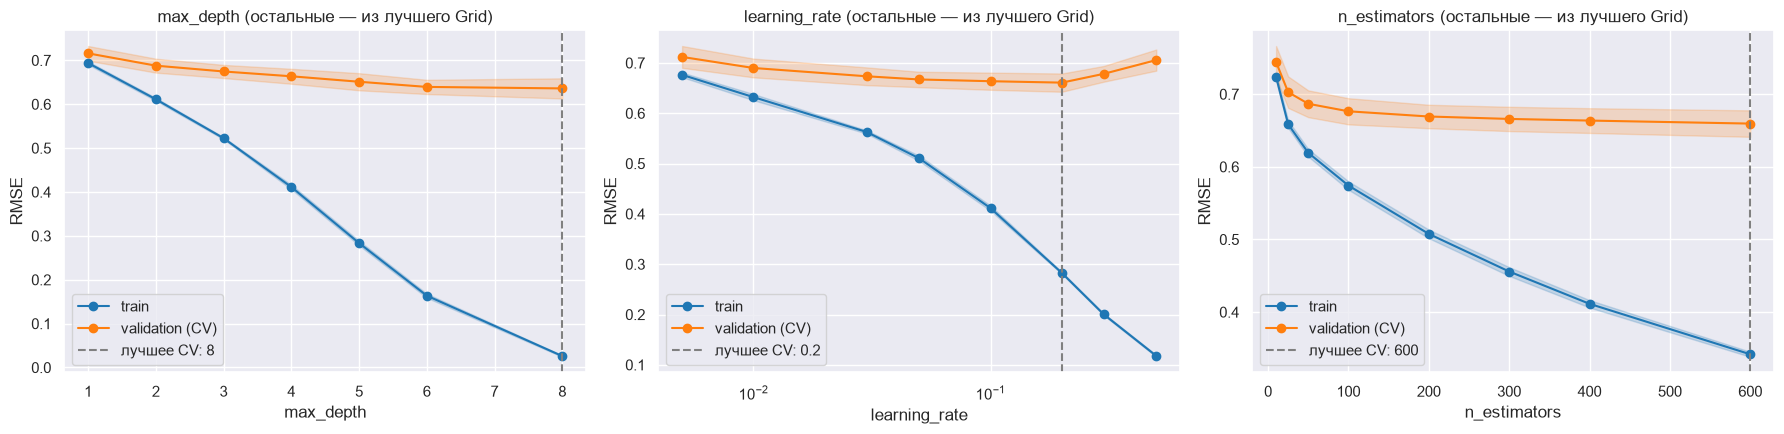

In [12]:
best_grid = grid.best_params_

def plot_validation_curve(param_name, param_range, ax, log_x=False):
    base = {k: v for k, v in best_grid.items() if k != param_name}
    est = GradientBoostingRegressor(random_state=RANDOM_STATE, **base)
    tr, va = validation_curve(est, X_train, y_train, param_name=param_name, param_range=param_range,
                              cv=cv, scoring=SCORING, n_jobs=-1)
    tr, va = -tr, -va
    for arr, label, color in [(tr, 'train', 'tab:blue'), (va, 'validation (CV)', 'tab:orange')]:
        m, s = arr.mean(axis=1), arr.std(axis=1)
        ax.plot(param_range, m, 'o-', label=label, color=color)
        ax.fill_between(param_range, m - s, m + s, alpha=0.2, color=color)
    best_x = param_range[int(np.argmin(va.mean(axis=1)))]
    ax.axvline(best_x, color='gray', ls='--', label=f'лучшее CV: {best_x}')
    if log_x: ax.set_xscale('log')
    ax.set_xlabel(param_name); ax.set_ylabel('RMSE'); ax.legend()
    ax.set_title(f'{param_name} (остальные — из лучшего Grid)')
    return pd.DataFrame({param_name: param_range, 'train': tr.mean(axis=1), 'val': va.mean(axis=1)})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
vc_depth = plot_validation_curve('max_depth', [1, 2, 3, 4, 5, 6, 8], axes[0])
vc_lr = plot_validation_curve('learning_rate', [0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5], axes[1], log_x=True)
vc_n = plot_validation_curve('n_estimators', [10, 25, 50, 100, 200, 300, 400, 600], axes[2])
plt.tight_layout(); plt.show()

### Интерпретация графиков

- **`max_depth`.** При глубине 1–2 деревья слишком простые: train и validation RMSE высоки и близки друг к другу — **недообучение**. С ростом глубины train RMSE быстро падает, а validation сначала улучшается (модель ловит взаимодействия признаков — зона **разумной сложности** около минимума), затем перестаёт улучшаться или растёт, и разрыв train–validation увеличивается — **переобучение**.
- **`learning_rate`.** При очень малом шаге при фиксированном числе деревьев ансамбль не успевает «дойти» до хорошего решения — **недообучение**. При слишком большом шаге модель быстро подгоняется под train (train RMSE низкий, validation хуже) — **переобучение**. Оптимум лежит между ними; шкала логарифмическая, т.к. важен порядок величины.
- **`n_estimators`.** Первые десятки деревьев резко снижают ошибку (**недообучение** при малом числе). Затем validation выходит на плато/минимум (**разумная сложность**), а train продолжает падать; при большом `n_estimators` разрыв растёт — **переобучение**. Положение оптимума зависит от `learning_rate`: чем меньше шаг, тем больше деревьев нужно (это видно на heatmap ниже).

(Точные значения оптимума и величина разрыва — см. графики и таблицу выше; они зависят от данных и от зафиксированных остальных параметров.)

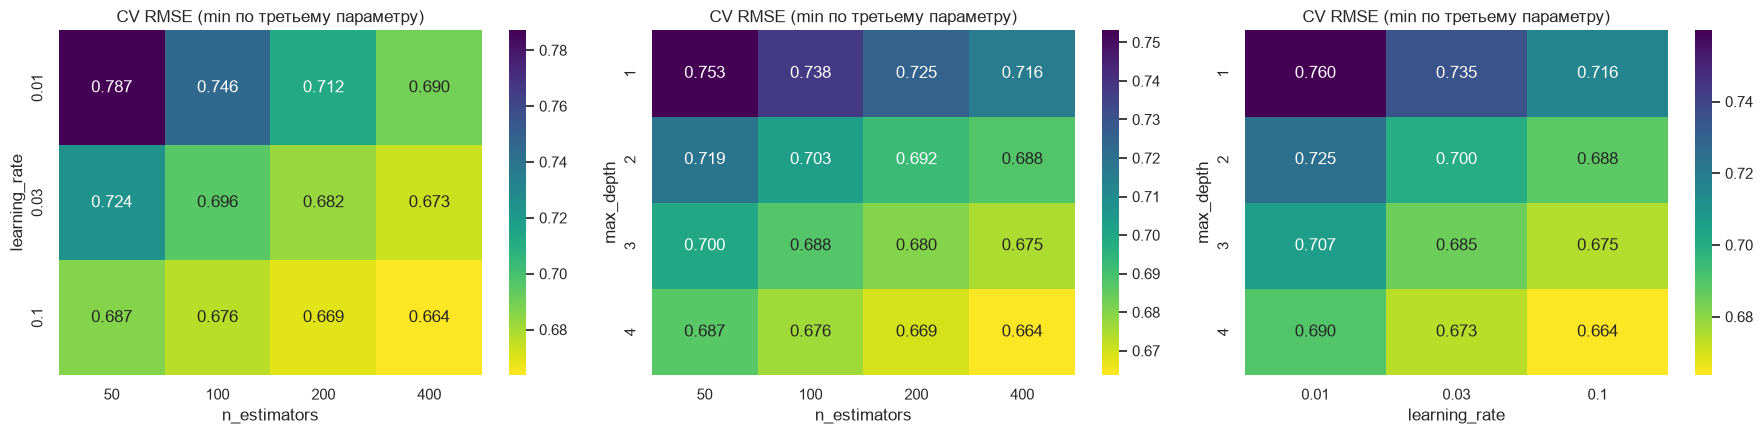

In [13]:
# Heatmap средней CV RMSE по сетке: для каждой пары параметров берём лучший результат по третьему
gr = grid_results.copy()
gr['CV RMSE'] = -gr['mean_test_score']
pairs = [('param_learning_rate', 'param_n_estimators'), ('param_max_depth', 'param_n_estimators'), ('param_max_depth', 'param_learning_rate')]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (r, c) in zip(axes, pairs):
    piv = gr.pivot_table(index=r, columns=c, values='CV RMSE', aggfunc='min')
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis_r', ax=ax)
    ax.set_title(f"CV RMSE (min по третьему параметру)")
    ax.set_ylabel(r.replace('param_', '')); ax.set_xlabel(c.replace('param_', ''))
plt.tight_layout(); plt.show()

**По heatmap:** видно взаимодействие `learning_rate` × `n_estimators` — при маленьком шаге (0.01) качество улучшается только при большом числе деревьев, а при шаге 0.1 оптимум достигается раньше. Глубина `max_depth=1` в большинстве ячеек заметно хуже — это та самая зона недообучения.

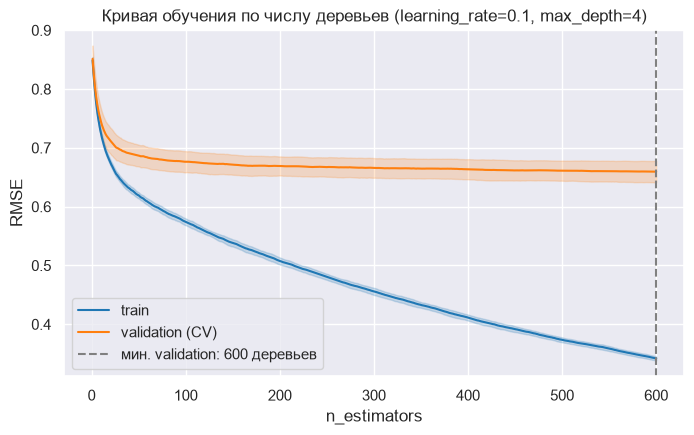

In [14]:
# Overfitting-картина по числу деревьев: staged_predict на лучших параметрах (одно обучение на фолд)
best_no_n = {k: v for k, v in best_grid.items() if k != 'n_estimators'}
n_max = 600
tr_curve, va_curve = [], []
for tr_idx, va_idx in cv.split(X_train):
    m = GradientBoostingRegressor(n_estimators=n_max, random_state=RANDOM_STATE, **best_no_n)
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    tr_curve.append([root_mean_squared_error(y_train.iloc[tr_idx], p) for p in m.staged_predict(X_train.iloc[tr_idx])])
    va_curve.append([root_mean_squared_error(y_train.iloc[va_idx], p) for p in m.staged_predict(X_train.iloc[va_idx])])
tr_curve, va_curve = np.array(tr_curve), np.array(va_curve)
xs = np.arange(1, n_max + 1)
plt.figure(figsize=(8, 4.5))
for arr, label, color in [(tr_curve, 'train', 'tab:blue'), (va_curve, 'validation (CV)', 'tab:orange')]:
    plt.plot(xs, arr.mean(axis=0), label=label, color=color)
    plt.fill_between(xs, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), alpha=0.2, color=color)
best_n = int(np.argmin(va_curve.mean(axis=0))) + 1
plt.axvline(best_n, color='gray', ls='--', label=f'мин. validation: {best_n} деревьев')
plt.xlabel('n_estimators'); plt.ylabel('RMSE'); plt.legend()
plt.title(f"Кривая обучения по числу деревьев (learning_rate={best_grid['learning_rate']}, max_depth={best_grid['max_depth']})")
plt.show()

## 7. Финальные модели и оценка на тесте

`GridSearchCV` и `RandomizedSearchCV` с `refit=True` уже **переобучили** лучшую конфигурацию на **всём train** (`best_estimator_`). Только теперь, один раз, обращаемся к тесту. Для каждой модели сравниваем CV-оценку (на train) и Test-оценку.

In [15]:
final_models = {
    'Baseline': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE).fit(X_train, y_train),
    'Grid Search (best)': grid.best_estimator_,
    'Random Search (best)': rand.best_estimator_,
}
fold_scores = {   # RMSE по фолдам (одинаковые фолды для всех)
    'Baseline': baseline_cv,
    'Grid Search (best)': -cross_val_score(GradientBoostingRegressor(random_state=RANDOM_STATE, **grid.best_params_), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1),
    'Random Search (best)': -cross_val_score(GradientBoostingRegressor(random_state=RANDOM_STATE, **rand.best_params_), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1),
}
rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    rows.append({
        'Модель': name,
        'Параметры': {k: (round(v, 4) if isinstance(v, float) else v) for k, v in model.get_params().items() if k in ['n_estimators', 'learning_rate', 'max_depth']},
        'CV RMSE (mean)': fold_scores[name].mean(),
        'CV RMSE (std)': fold_scores[name].std(),
        'Test RMSE': root_mean_squared_error(y_test, pred),
        'Test MAE': mean_absolute_error(y_test, pred),
    })
final_df = pd.DataFrame(rows).set_index('Модель')
final_df['Δ Test RMSE vs baseline'] = final_df['Test RMSE'] - final_df.loc['Baseline', 'Test RMSE']
display(final_df)

,Параметры,CV RMSE (mean),CV RMSE (std),Test RMSE,Test MAE,Δ Test RMSE vs baseline
Модель,,,,,,
Baseline,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.687640,0.017063,0.678413,0.532242,0.000000
Grid Search (best),"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.663641,0.017059,0.644087,0.491313,-0.034325
Random Search (best),"{'learning_rate': 0.1863, 'max_depth': 5, 'n_e...",0.653400,0.019736,0.632272,0.450947,-0.046141


In [16]:
base_cv, base_te = final_df.loc['Baseline', ['CV RMSE (mean)', 'Test RMSE']]
for name in ['Grid Search (best)', 'Random Search (best)']:
    cv_gain = base_cv - final_df.loc[name, 'CV RMSE (mean)']
    te_gain = base_te - final_df.loc[name, 'Test RMSE']
    print(f"{name}: улучшение CV RMSE = {cv_gain:+.4f} ({cv_gain / base_cv:+.1%}), улучшение Test RMSE = {te_gain:+.4f} ({te_gain / base_te:+.1%}); "
          f"gap CV−Test = {final_df.loc[name, 'CV RMSE (mean)'] - final_df.loc[name, 'Test RMSE']:+.4f}")

Grid Search (best): улучшение CV RMSE = +0.0240 (+3.5%), улучшение Test RMSE = +0.0343 (+5.1%); gap CV−Test = +0.0196
Random Search (best): улучшение CV RMSE = +0.0342 (+5.0%), улучшение Test RMSE = +0.0461 (+6.8%); gap CV−Test = +0.0211


### Ответы на вопросы

**Насколько оптимизация улучшила качество?** Смотрите строки `Δ Test RMSE vs baseline` и вывод ячейки выше. Baseline (`lr=0.1, depth=3, 100 деревьев`) уже находится в разумной области пространства параметров, поэтому ожидаемый выигрыш от тюнинга скромный — единицы процентов RMSE, а не кратное улучшение. Главный практический результат — найденная конфигурация лучше baseline и по CV, и (проверяем) по тесту.

**Совпадает ли улучшение по CV с улучшением на тесте?** Обычно — частично, но не в точности. Причины расхождения:
1. **Оптимистичный выбор (selection bias).** Из 48 конфигураций мы выбрали ту, у которой максимальный CV-score; часть её преимущества — случайность на конкретных фолдах (выбор максимума из шумных оценок). Поэтому CV-оценка лучшей конфигурации слегка завышена по сравнению с реальным качеством.
2. **Шум конечного теста.** Тест — 1300 объектов, его RMSE имеет собственную ошибку; разница в 0.005–0.01 RMSE может быть в пределах этого шума.
3. **Разный размер обучающей выборки.** В CV модель обучалась на 80% train, финальная — на 100% train.
4. **Малая разница между конфигурациями.** Если разница между baseline и лучшей моделью меньше `CV std`, она статистически неотличима от нуля, и на тесте знак разницы может измениться.

Если на тесте улучшение оказалось меньше, чем по CV, это нормально и объясняется пунктами 1–2; если оно **противоположно** — значит, улучшение по CV было в пределах шума.

**Grid vs Random.** Если CV RMSE и Test RMSE двух методов различаются меньше, чем `CV std`, считаем их равнозначными: при одинаковом бюджете оба нашли «плато» хороших конфигураций.

## 8. Стабильность моделей

Средний CV-score не показывает, насколько результат зависит от разбиения. Смотрим результаты по фолдам и разброс (std).

,Baseline,Grid Search (best),Random Search (best)
fold 1,0.7118,0.6876,0.6593
fold 2,0.6651,0.6496,0.6567
fold 3,0.6834,0.6521,0.6419
fold 4,0.7020,0.6810,0.6843
fold 5,0.6759,0.6478,0.6248


,Baseline,Grid Search (best),Random Search (best)
mean,0.6876,0.6636,0.6534
std,0.0191,0.0191,0.0221
min,0.6651,0.6478,0.6248
max,0.7118,0.6876,0.6843


C:\Users\mrkir\AppData\Local\Temp\ipykernel_14916\3196523261.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=long, x='Модель', y='RMSE', ax=ax, size=8, jitter=False, palette='viridis')


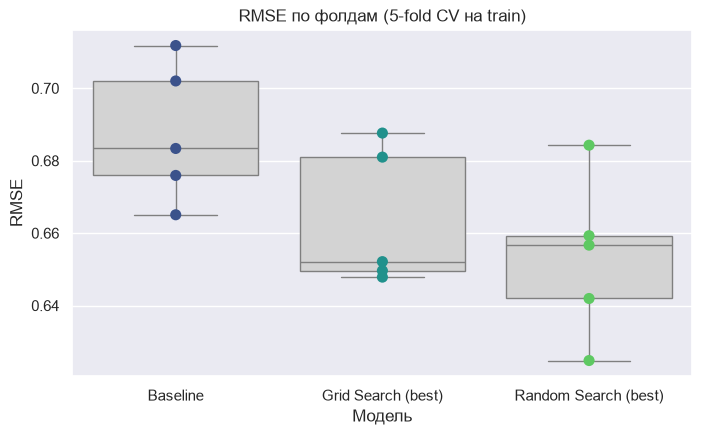

In [17]:
folds_df = pd.DataFrame(fold_scores, index=[f'fold {i+1}' for i in range(CV_FOLDS)])
display(folds_df.round(4))
display(folds_df.agg(['mean', 'std', 'min', 'max']).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
long = folds_df.melt(var_name='Модель', value_name='RMSE')
sns.boxplot(data=long, x='Модель', y='RMSE', ax=ax, color='lightgray')
sns.stripplot(data=long, x='Модель', y='RMSE', ax=ax, size=8, jitter=False, palette='viridis')
ax.set_title('RMSE по фолдам (5-fold CV на train)')
plt.show()

**Почему две модели с одинаковым средним CV могут отличаться по стабильности.** Среднее скрывает распределение: одна модель может давать почти одинаковый результат на всех фолдах (малый std), а другая — «то лучше, то хуже» (большой std) при том же среднем. Причины:
- более сложная модель (глубокие деревья, большой `learning_rate`, много деревьев) имеет **большую дисперсию** — сильнее реагирует на состав обучающей выборки и отдельные выбросы;
- простая или сильно регуляризованная модель (малый шаг, неглубокие деревья) имеет большее смещение, но **более стабильна**;
- разные фолды содержат разные «трудные» объекты (редкие оценки 3, 8, 9 в Wine Quality), и чувствительность моделей к ним разная.

На практике при близком среднем предпочитают модель с меньшим std (и более простую): она надёжнее будет вести себя на новых данных. Оцените это по таблице и boxplot выше. Фолды одни и те же для всех моделей, поэтому сравнение попарное и корректное.

## 9. Честность эксперимента

- Тестовая выборка **не использовалась** при выборе гиперпараметров, числа фолдов, диапазонов поиска и интерпретации графиков: все решения принимались по CV на train. К тесту мы обратились один раз — в разделе 7, после того как финальные конфигурации были зафиксированы.
- Подбор гиперпараметров по тесту — **критическая ошибка**: тест перестаёт быть независимой оценкой, и итоговая метрика становится оптимистично завышенной (утечка информации о тесте в выбор модели). Если после подбора мы видим плохой результат на тесте, нельзя «подкрутить» параметры по нему — это снова превратит тест в валидацию. Правильный путь — менять пространство поиска/модель и оценивать по CV; новый тест нужно брать из новых данных.
- В baseline нет предобработки (деревья не требуют масштабирования), поэтому утечки через препроцессинг нет; при добавлении масштабирования/отбора признаков нужно оборачивать их в `Pipeline` вместе с моделью и передавать в поиск, чтобы они обучались внутри каждого фолда.
- Все random_state зафиксированы (`RANDOM_STATE = 42`), результаты воспроизводимы; полные таблицы поиска сохранены в `grid_results.csv` и `random_results.csv`.

## 10. Итоговые выводы
1. Выбраны три гиперпараметра (`n_estimators`, `learning_rate`, `max_depth`) с обоснованием диапазонов; для подбора использована 5-fold CV на train.
2. Grid Search (48 комбинаций) и Random Search (48 комбинаций, тот же бюджет) нашли близкие по качеству конфигурации; точные параметры, CV и Test см. в итоговой таблице раздела 7.
3. Графики показывают три режима: недообучение (простые модели / мало деревьев / слишком малый шаг), разумную сложность (минимум validation RMSE) и переобучение (рост разрыва train–validation).
4. Улучшение от тюнинга умеренное; CV-оценка лучшей модели чуть оптимистичнее теста из-за отбора лучшей из многих конфигураций.
5. Модели оценивались и по среднему, и по разбросу по фолдам — при близком среднем важна стабильность.